## Actividad 2.1
#### Juan Angel Galvan Navarro 611380

## Definición del problema de clasificación 
La base de datos original no contiene una variable cualitativa de interés directamente utilizable, por lo que se construye una a partir de `Edad_madn` (variable continua usada en el proyecto anterior). Se define la variable binaria `embarazo_adolescente`:

- 1 si Edad_madn está entre 10 y 19 años (inclusive)
- 0 si Edad_madn es 20 años o más

El criterio de corte no es arbitrario: la Organización Mundial de la Salud define el embarazo adolescente como aquel que ocurre entre los 10 y 19 años (World Health Organization: WHO, 2024), por lo que el umbral de 20 años tiene respaldo médico/institucional, no es una división estadística inventada para el ejercicio.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from dbfread import DBF

In [4]:
table = DBF('nacim24.dbf', encoding='latin1')
print(table.field_names)


['ENT_REGIS', 'MUN_REGIS', 'LOC_REGIS', 'TLOC_REGIS', 'ENT_RESID', 'MUN_RESID', 'LOC_RESID', 'TLOC_RESID', 'ENT_OCURR', 'MUN_OCURR', 'LOC_OCURR', 'TLOC_OCURR', 'SEXO', 'EDAD_REG', 'EDAD_MADN', 'EDAD_PADN', 'DIA_NAC', 'MES_NAC', 'ANO_NAC', 'DIA_REG', 'MES_REG', 'ANO_REG', 'EDAD_MADR', 'EDAD_PADR', 'TIPO_NAC', 'ORDEN_PART', 'LUGAR_PART', 'Q_ATENDIO', 'HIJOS_VIVO', 'HIJOS_SOBR', 'EDOCIV_MAD', 'ESCOL_MAD', 'ESCOL_PAD', 'ACT_MAD', 'ACT_PAD', 'POS_MAD', 'POS_PAD', 'SITLAB_MAD', 'SITLAB_PAD', 'FUE_PRESE', 'HORA_NAC', 'MINUTO_NAC', 'COMPARECIO', 'DIS_RE_OAX']


In [5]:
cols = ['ENT_REGIS', 'MUN_REGIS', 'LOC_REGIS', 'TLOC_REGIS', 'ENT_RESID', 'MUN_RESID', 'LOC_RESID', 'TLOC_RESID', 'ENT_OCURR', 'MUN_OCURR', 'LOC_OCURR', 'TLOC_OCURR', 'SEXO', 'EDAD_REG', 'EDAD_MADN', 'EDAD_PADN', 'DIA_NAC', 'MES_NAC', 'ANO_NAC', 'DIA_REG', 'MES_REG', 'ANO_REG', 'EDAD_MADR', 'EDAD_PADR', 'TIPO_NAC', 'ORDEN_PART', 'LUGAR_PART', 'Q_ATENDIO', 'HIJOS_VIVO', 'HIJOS_SOBR', 'EDOCIV_MAD', 'ESCOL_MAD', 'ESCOL_PAD', 'ACT_MAD', 'ACT_PAD', 'POS_MAD', 'POS_PAD', 'SITLAB_MAD', 'SITLAB_PAD', 'FUE_PRESE', 'HORA_NAC', 'MINUTO_NAC', 'COMPARECIO', 'DIS_RE_OAX']
data = pd.DataFrame([[rec[c] for c in cols] for rec in table], columns=cols)
data = pd.DataFrame([[rec[c] for c in cols] for rec in table], columns=cols)
data.head()

,ENT_REGIS,MUN_REGIS,LOC_REGIS,TLOC_REGIS,ENT_RESID,MUN_RESID,LOC_RESID,TLOC_RESID,ENT_OCURR,MUN_OCURR,...,ACT_PAD,POS_MAD,POS_PAD,SITLAB_MAD,SITLAB_PAD,FUE_PRESE,HORA_NAC,MINUTO_NAC,COMPARECIO,DIS_RE_OAX
0,01,003,0055,5,01,003,0001,8,01,001,...,1,9,3,2,1,1,18,29,3,999
1,01,007,0001,9,01,007,0001,9,01,005,...,1,9,1,3,1,1,1,35,3,999
2,01,001,0001,15,01,003,0001,8,01,001,...,9,9,9,3,9,1,20,0,2,999
3,01,001,0001,15,01,001,0001,15,01,001,...,1,9,1,3,1,1,12,0,3,999
4,01,001,0001,15,01,001,0001,15,01,001,...,1,4,4,1,1,1,21,45,3,999


In [6]:
# Limpieza: mismos criterios de calidad de datos usados en el proyecto anterior
clean = data[(data.EDAD_MADN != 99) & (data.ESCOL_MAD != 9) &
             (data.EDOCIV_MAD != 9) & (data.ACT_MAD != 9) &
             (data.TLOC_RESID != 99)].copy()
#Se eliminaba Hijos por su correlacion
clean = clean.drop(columns=["HIJOS_VIVO"])


# Variable binaria de clasificación (embarazo adolescente según definición de la OMS: 10-19 años)
clean["embarazo_adolescente"] = (clean.EDAD_MADN <= 19).astype(int)
clean["ACT_MAD"] = clean["ACT_MAD"].map({1: 1, 2: 0})
clean = pd.get_dummies(clean, columns=["EDOCIV_MAD"], prefix="edociv", drop_first=True)
clean = pd.get_dummies(clean, columns=["ENT_RESID"], prefix="ent", drop_first=True) 

print(clean.embarazo_adolescente.value_counts())
print(clean.embarazo_adolescente.value_counts(normalize=True).round(4) * 100)

embarazo_adolescente
0    1028500
1     168065
Name: count, dtype: int64
embarazo_adolescente
0    85.95
1    14.05
Name: proportion, dtype: float64


## Separación de datos y balance de clases

In [7]:
# División entrenamiento/prueba, estratificada para conservar el balance de clases (85.95% / 14.05%)
train, test = train_test_split(
    clean,
    test_size=0.2,
    stratify=clean["embarazo_adolescente"],
    random_state=10
)

print("Original:", clean.embarazo_adolescente.value_counts(normalize=True).round(4).to_dict())
print("Train:   ", train.embarazo_adolescente.value_counts(normalize=True).round(4).to_dict())
print("Test:    ", test.embarazo_adolescente.value_counts(normalize=True).round(4).to_dict())
print()
print("Filas train:", len(train), " Filas test:", len(test))

Original: {0: 0.8595, 1: 0.1405}
Train:    {0: 0.8595, 1: 0.1405}
Test:     {0: 0.8595, 1: 0.1405}

Filas train: 957252  Filas test: 239313


Como se observa en el resultado del código, los datos fueron dividiso conservando el balance de las clases tanto en train como en test

## Validación cruzada (10-fold, estratificada, solo con entrenamiento)

In [24]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def ajustar_logistica(X, y, iters=25, tol=1e-6):
    Xm = np.column_stack([np.ones(len(y)), X])
    n, k = Xm.shape
    beta = np.zeros(k)
    for i in range(iters):
        p = np.clip(sigmoid(Xm @ beta), 1e-10, 1 - 1e-10)
        W = p * (1 - p)
        grad = Xm.T @ (y - p)
        H = Xm.T @ (Xm * W[:, None])       # matriz Hessiana
        delta = np.linalg.solve(H, grad)   # paso de Newton-Raphson (IRLS)
        beta += delta
        if np.max(np.abs(delta)) < tol:
            break
    return beta

def predecir_proba(X, beta):
    Xm = np.column_stack([np.ones(len(X)), X])
    return sigmoid(Xm @ beta)

def metricas(y, p, umbral=0.2):
    pred = (p >= umbral).astype(int)
    TP = np.sum((pred==1)&(y==1)); TN = np.sum((pred==0)&(y==0))
    FP = np.sum((pred==1)&(y==0)); FN = np.sum((pred==0)&(y==1))
    exactitud = (TP+TN)/len(y)
    sensibilidad = TP/(TP+FN) if (TP+FN)>0 else np.nan
    especificidad = TN/(TN+FP) if (TN+FP)>0 else np.nan
    return exactitud, sensibilidad, especificidad

def auc_manual(y, p):
    orden = np.argsort(p)
    ranks = np.empty(len(p)); ranks[orden] = np.arange(1, len(p)+1)
    n1, n0 = np.sum(y==1), np.sum(y==0)
    return (np.sum(ranks[y==1]) - n1*(n1+1)/2) / (n1*n0)


In [25]:
# Particiones en 10 folds, estratificadas (por separado en positivos y negativos)

def build_X(df, nolineal=False):
    escol = df["ESCOL_MAD"].values.astype(float)
    act = df["ACT_MAD"].values.astype(float)
    orden = df["ORDEN_PART"].values.astype(float)
    edociv2 = df["edociv_2"].values.astype(float)
    if nolineal:
        return np.column_stack([escol, escol**2, escol**3, act, orden, edociv2])
    return np.column_stack([escol, act, orden, edociv2])

X_train_full = build_X(train)
y_train_full = train["embarazo_adolescente"].values.astype(float)

np.random.seed(10)
idx_pos = np.where(y_train_full == 1)[0]; np.random.shuffle(idx_pos)
idx_neg = np.where(y_train_full == 0)[0]; np.random.shuffle(idx_neg)
folds_pos = np.array_split(idx_pos, 10)
folds_neg = np.array_split(idx_neg, 10)

resultados = []
for k in range(10):
    idx_val = np.concatenate([folds_pos[k], folds_neg[k]])
    idx_fit = np.setdiff1d(np.arange(len(y_train_full)), idx_val)

    beta = ajustar_logistica(X_train_full[idx_fit], y_train_full[idx_fit])
    p = predecir_proba(X_train_full[idx_val], beta)

    exact, sens, espec = metricas(y_train_full[idx_val], p)
    auc = auc_manual(y_train_full[idx_val], p)
    resultados.append((exact, sens, espec, auc))

resultados = np.array(resultados)
print("Media -> Exactitud: {:.4f}  Sensibilidad: {:.4f}  Especificidad: {:.4f}  AUC: {:.4f}".format(*resultados.mean(axis=0)))
print("Std   -> Exactitud: {:.4f}  Sensibilidad: {:.4f}  Especificidad: {:.4f}  AUC: {:.4f}".format(*resultados.std(axis=0)))

Media -> Exactitud: 0.8133  Sensibilidad: 0.7811  Especificidad: 0.8186  AUC: 0.8697
Std   -> Exactitud: 0.0087  Sensibilidad: 0.0048  Especificidad: 0.0105  AUC: 0.0025


### Reflexión sobre la validación cruzada

Los 10 folds arrojan resultados muy consistentes entre sí (desviaciones estándar mínimas: 0.0087 en exactitud, 0.0048 en sensibilidad, 0.0105 en especificidad, 0.0025 en AUC), lo que da confianza de que estas métricas son un estimador estable del desempeño esperado del modelo, a diferencia de una sola partición entrenamiento-prueba que dependería del azar de esa única división.

La exactitud (81.3%) es alta y algo similar a simplemente predecir siempre "no es embarazo adolescente" (86.0%, dado el desbalance de clases). La sensibilidad (78.11) ayuda a resolver el caso de los embarazos adolescentes. Se pueden detectar 78 de 100 casos de embarazos adolescentes, reduciendo mucho los casos de falsos negativos. Esto fue gracias a que el umbral fue modificado del estandar 0.5 a 0.2. Se perdió un poco de exactitud, a costa de identificar la mayoria de los casos de embarazos adolescentes.

## Entrenamiento final y evaluación en prueba

Se entrena el modelo de regresión logística usando la totalidad del conjunto de entrenamiento (957,252 filas), y se evalúa una sola vez sobre el conjunto de prueba independiente (239,313 filas), que no participó ni en el entrenamiento ni en la validación cruzada.

In [26]:
X_train, y_train = build_X(train), train["embarazo_adolescente"].values.astype(float)
X_test, y_test = build_X(test), test["embarazo_adolescente"].values.astype(float)

beta_final = ajustar_logistica(X_train, y_train)
p_test = predecir_proba(X_test, beta_final)

def metricas_completas(y, p, umbral=0.2):
    pred = (p >= umbral).astype(int)
    TP = np.sum((pred==1)&(y==1)); TN = np.sum((pred==0)&(y==0))
    FP = np.sum((pred==1)&(y==0)); FN = np.sum((pred==0)&(y==1))
    exact = (TP+TN)/len(y)
    sens = TP/(TP+FN) if (TP+FN)>0 else np.nan
    espec = TN/(TN+FP) if (TN+FP)>0 else np.nan
    return exact, sens, espec, TP, TN, FP, FN

exact, sens, espec, TP, TN, FP, FN = metricas_completas(y_test, p_test)
auc_test = auc_manual(y_test, p_test)

print("Matriz de confusión (umbral = 0.2):")
print(f"              Predicho 0   Predicho 1")
print(f"Real 0 (no)   {TN:10d}   {FP:10d}")
print(f"Real 1 (sí)   {FN:10d}   {TP:10d}")
print()
print(f"Exactitud: {exact:.4f}  Sensibilidad: {sens:.4f}  Especificidad: {espec:.4f}  AUC: {auc_test:.4f}")

Matriz de confusión (umbral = 0.2):
              Predicho 0   Predicho 1
Real 0 (no)       165644        40056
Real 1 (sí)         7413        26200

Exactitud: 0.8016  Sensibilidad: 0.7795  Especificidad: 0.8053  AUC: 0.8701


### Comparación validación cruzada vs. conjunto de prueba

| Métrica | Validación cruzada (media) | Prueba independiente |
|---|---|---|
| Exactitud | 0.8133 | 0.8016 |
| Sensibilidad | 0.7811 | 0.7795 |
| Especificidad | 0.8186 | 0.8053 |
| AUC | 0.8697 | 0.8701 |

Las métricas de prueba son prácticamente idénticas a las estimadas por validación cruzada (diferencias de centésimas o milésimas, dentro del rango de variación entre folds ya observado). Esto confirma que la validación cruzada cumplió su propósito: dio una estimación confiable y no optimista del desempeño esperado del modelo antes de tocar siquiera el conjunto de prueba. De los 33,613 casos reales de embarazo adolescente en prueba, el modelo con umbral 0.2 identifica correctamente 25,201 (0.78%), lo cual se puede considerar un buen margen para la identificación de los casos.

## Curva ROC y AUC 

In [27]:
def curva_roc(y, p, n_puntos=200):
    umbrales = np.linspace(1, 0, n_puntos)
    tpr_list, fpr_list = [], []
    n1, n0 = np.sum(y==1), np.sum(y==0)
    for u in umbrales:
        pred = (p >= u).astype(int)
        TP = np.sum((pred==1)&(y==1)); FP = np.sum((pred==1)&(y==0))
        tpr_list.append(TP/n1)
        fpr_list.append(FP/n0)
    return np.array(fpr_list), np.array(tpr_list)

fpr, tpr = curva_roc(y_test, p_test)

def auc_trapecio(fpr, tpr):
    return np.sum((fpr[1:] - fpr[:-1]) * (tpr[1:] + tpr[:-1]) / 2)

auc_roc = auc_trapecio(fpr, tpr)
print("AUC:", auc_roc)

AUC: 0.8700866279556716


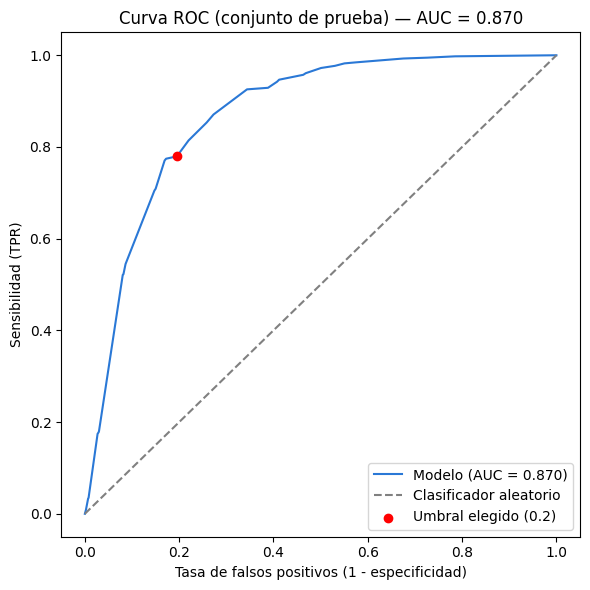

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color="#2a78d6", label=f"Modelo (AUC = {auc_roc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Clasificador aleatorio")

pred02 = (p_test >= 0.2).astype(int)
TP = np.sum((pred02==1)&(y_test==1)); FP = np.sum((pred02==1)&(y_test==0))
n1, n0 = np.sum(y_test==1), np.sum(y_test==0)
plt.scatter([FP/n0], [TP/n1], color="red", zorder=5, label="Umbral elegido (0.2)")

plt.xlabel("Tasa de falsos positivos (1 - especificidad)")
plt.ylabel("Sensibilidad (TPR)")
plt.title(f"Curva ROC (conjunto de prueba) — AUC = {auc_roc:.3f}")
plt.legend()
plt.tight_layout()
plt.show()

La curva ROC muestra la sensibilidad (tasa de verdaderos positivos) contra la tasa de falsos positivos en todos los umbrales posibles, sin fijar uno solo. El AUC de 0.87 se interpreta como: si se toma al azar un caso real de embarazo adolescente y uno que no lo es, el modelo asigna una probabilidad más alta al caso positivo el 87% de las veces. Un valor de 0.87 indica una capacidad discriminativa buena (bastante por encima de 0.5, que sería equivalente a adivinar al azar).

El punto correspondiente al umbral elegido (0.2) se ubica en (FPR=0.195, TPR=0.779): se acepta un 19.5% de falsas alarmas para lograr detectar al 77.9% de los casos reales, un punto razonable dentro de la curva dado que el objetivo prioriza no dejar pasar casos de embarazo adolescente.

## Interpretación del modelo

In [29]:
import numpy as np

nombres = ["Intercepto", "Escol_mad", "Act_mad", "Orden_part", "edociv_2"]
odds_ratio = np.exp(beta_final)

for nom, b, orr in zip(nombres, beta_final, odds_ratio):
    print(f"{nom:12s} beta={b:8.4f}  OR=exp(beta)={orr:.4f}")

Intercepto   beta=  4.5113  OR=exp(beta)=91.0383
Escol_mad    beta= -0.5626  OR=exp(beta)=0.5697
Act_mad      beta= -0.9128  OR=exp(beta)=0.4014
Orden_part   beta= -1.9592  OR=exp(beta)=0.1410
edociv_2     beta= -1.6715  OR=exp(beta)=0.1880


Los cuatro coeficientes son negativos: todas las variables reducen la probabilidad de embarazo adolescente, ninguna la aumenta.

- **Escol_mad** (OR = 0.57): cada nivel adicional de escolaridad reduce a poco más de la mitad la razón de momios de que el nacimiento corresponda a una madre adolescente. Es consistente con lo esperado: una madre adolescente ha tenido, por definición, menos tiempo de vida para acumular escolaridad.
- **Act_mad** (OR = 0.40): que la madre trabaje reduce la razón de momios en un 60% aproximadamente frente a no trabajar. Tiene sentido en el mismo sentido: incorporarse al mercado laboral formal suele ocurrir después de la adolescencia.
- **Orden_part** (OR = 0.14): es el efecto más fuerte del modelo. Cada nacimiento adicional en el orden de parto reduce drásticamente la razón de momios de que sea un embarazo adolescente — es mecánicamente esperado, ya que un segundo, tercer o cuarto hijo requiere que haya transcurrido tiempo desde un primer nacimiento, lo que hace muy poco probable que la madre siga siendo adolescente.
- **edociv_2 (casada)** (OR = 0.19): estar casada reduce fuertemente la razón de momios frente a estar soltera (la categoría de referencia). Es coherente con el contexto social: el matrimonio suele ocurrir en edades posteriores a la adolescencia.

**Coherencia con la problemática original:** estos resultados son consistentes con el estudio de inferencia del proyecto anterior, donde ya se había encontrado que menor escolaridad, no trabajar, y ser soltera se asociaban con una edad materna más baja. El modelo de clasificación confirma la misma historia, ahora expresada en términos de probabilidad de pertenecer al grupo de mayor riesgo (embarazo adolescente) en lugar de la edad exacta esperada.

**Limitación a señalar:** dos de las variables más influyentes del modelo (`Orden_part` y, en parte, `edociv_2`) tienen una relación en buena medida mecánica con la edad (un segundo parto requiere tiempo; casarse suele requerir mayoría de edad legal), por lo que el modelo separa bien las clases, pero su valor como herramienta de intervención temprana es limitado — no está identificando factores de riesgo *antes* del embarazo, sino características que ya reflejan que este ya no es el primer evento reproductivo o de estado civil de la madre. Me gustaría ver un dataset que nos permita añadir variables que se puedan identificar a temprana edad, para poder tener un modelo que pueda apoyar en ciertas medidas a prevenir embarazos adolescentes.

### Doy mi palabra que he realizado esta actividad con integridad academica.
### Referencias bibliograficas
- World Health Organization: WHO. (2024, April 10). Adolescent pregnancy. Translate.Goog; World Health Organization: WHO. https://www.who.int/news-room/fact-sheets/detail/adolescent-pregnancy

*Nota: Se uso IAG para la generación de código nuevo, y para la redacción correcta de los análisis.*
